# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import VALIDSemanticSegmentationDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
import csv
import matplotlib.pyplot as plt

## Visualize images and masks

Total number of patches: 6689


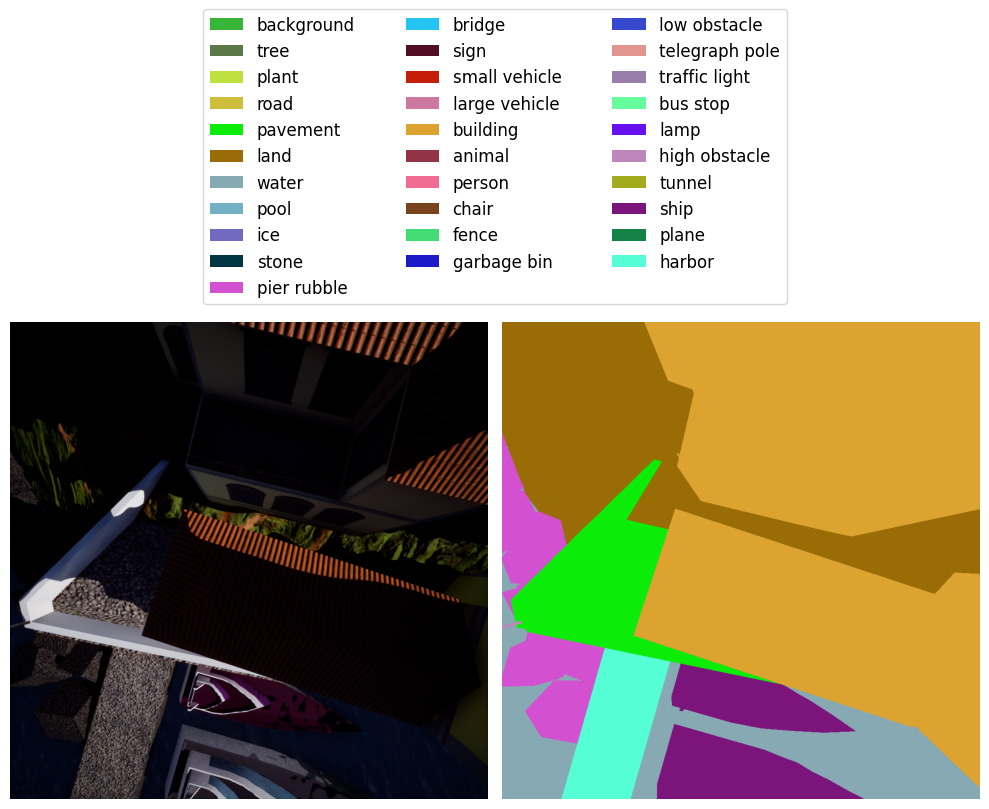

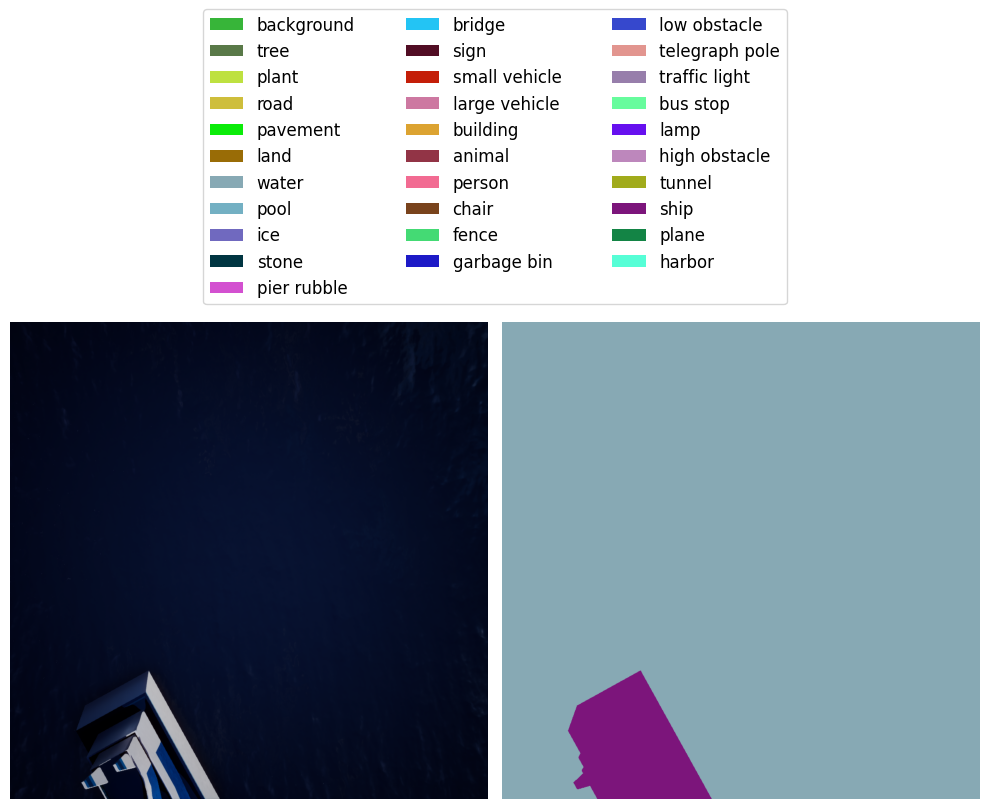

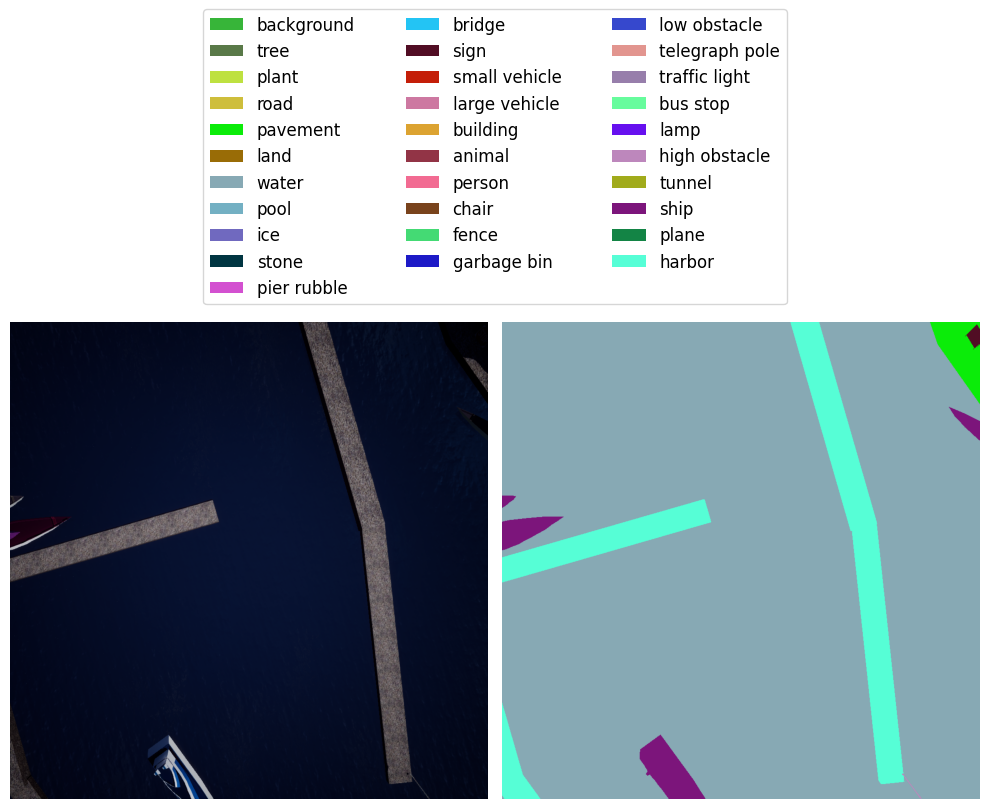

In [ ]:
dataset_config = {
    "data_dir": "./data/valid_semantic_segmentation/",
}
dataset = VALIDSemanticSegmentationDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(350);
dataset.show_image(700);

In [20]:
dataset.data_distribution_table()

,Number of pixels
background,1.074850e+05
tree,5.551230e+08
plant,9.682837e+07
road,1.490251e+09
pavement,9.328892e+08
land,1.730344e+09
water,4.284040e+08
pool,8.220175e+06
ice,1.064199e+08
stone,2.030946e+07


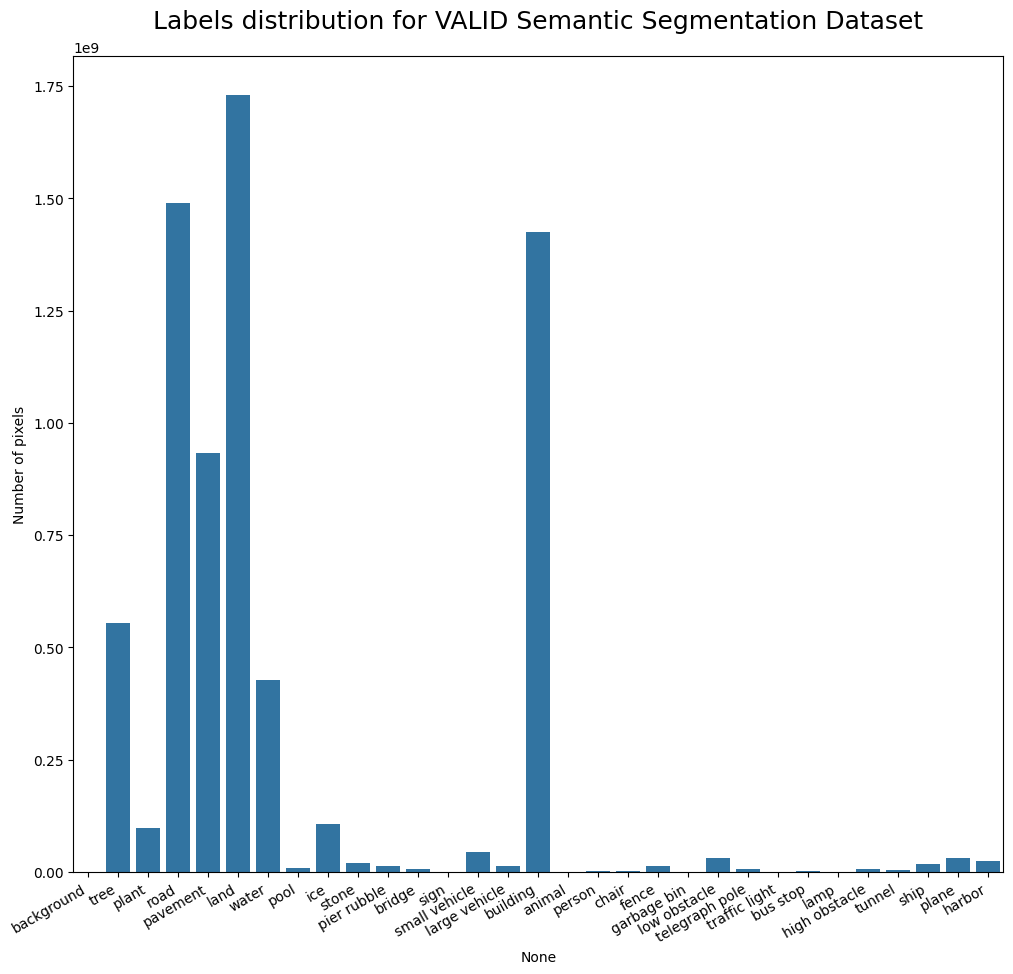

In [21]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/valid_semantic_segmentation/",
    "csv_file": "./data/valid_semantic_segmentation/valid_train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = VALIDSemanticSegmentationDataset(train_dataset_config)
len(train_dataset)

5352

## Create the model

In [ ]:
epochs = 2
model_directory = "./data/experiments/valid_semantic_segmentation"
model_config = {
    "num_classes": 31, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-11-05 07:44:32,366 INFO Starting training.
training: 100%|██████████| 669/669 [2:14:31<00:00, 12.06s/it]
2025-11-05 09:59:03,456 INFO epoch: 1, time: 8071, loss:  0.54698
testing on train set: 100%|██████████| 669/669 [2:21:56<00:00, 12.73s/it]  
2025-11-05 12:21:01,993 INFO IOU:0.7480392498466994, IOU mean:0.16439284565286535, IOU per Class:[0.         0.41166343 0.         0.82203234 0.74898338 0.74107755
 0.9402591  0.         0.57383578 0.         0.         0.
 0.         0.         0.         0.85832663 0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.        ]
training: 100%|██████████| 669/669 [3:47:01<00:00, 20.36s/it]
2025-11-05 16:08:03,064 INFO epoch: 2, time: 13622, loss:  0.16058
testing on train set: 100%|██████████| 669/669 [4:08:54<00:00, 22.32s/it]  
2025-11-05 20:16:57,299 INFO IOU:0.7953650218079562, IOU mean:0.1825483978490342, IOU per Class:[0.         0.40809348 0.         

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/valid_semantic_segmentation/",
    "csv_file": "./data/valid_semantic_segmentation/valid_val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = VALIDSemanticSegmentationDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/valid_semantic_segmentation/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

669


2025-11-06 07:35:55,504 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/valid_semantic_segmentation/checkpoint.pth.tar
2025-11-06 07:35:55,854 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/valid_semantic_segmentation/checkpoint.pth.tar at epoch 3
testing on test set: 100%|██████████| 168/168 [17:22<00:00,  6.21s/it]


[{'IOU': 0.7889542134667842,
  'IOU mean': 0.18176195736638415,
  'IOU per Class': array([0.        , 0.41885843, 0.        , 0.86234513, 0.80094005,
         0.81504743, 0.93999185, 0.        , 0.91238779, 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.88505001, 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        ])}]

## Predictions

In [11]:
'''
The predictions will give 31 masks (one per class). 
This function rearranges the figure to make it more readable.
'''
import math
def rearrange_figure_to_grid(fig, cols=8):
    original_axes = fig.axes
    num_plots = len(original_axes)
    rows = math.ceil(num_plots / cols)

    # Create a new figure
    new_fig, new_axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.5))
    new_axes = new_axes.flatten()

    for i, old_ax in enumerate(original_axes):
        # Extract the image and title
        im = old_ax.images[0] if old_ax.images else None
        title = old_ax.get_title()

        # Copy to new axis
        if im:
            new_axes[i].imshow(im.get_array(), cmap=im.get_cmap())
            new_axes[i].set_title(title, fontsize=13)
        new_axes[i].axis('off')

    # Turn off any unused subplots
    for j in range(i + 1, len(new_axes)):
        new_axes[j].axis('off')

    plt.tight_layout()
    return new_fig

2025-11-06 08:01:47,204 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/valid_semantic_segmentation/checkpoint.pth.tar
2025-11-06 08:01:47,684 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/valid_semantic_segmentation/checkpoint.pth.tar at epoch 3


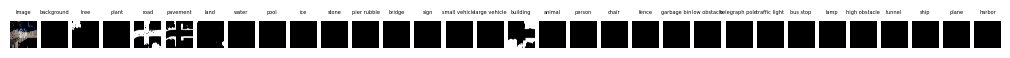

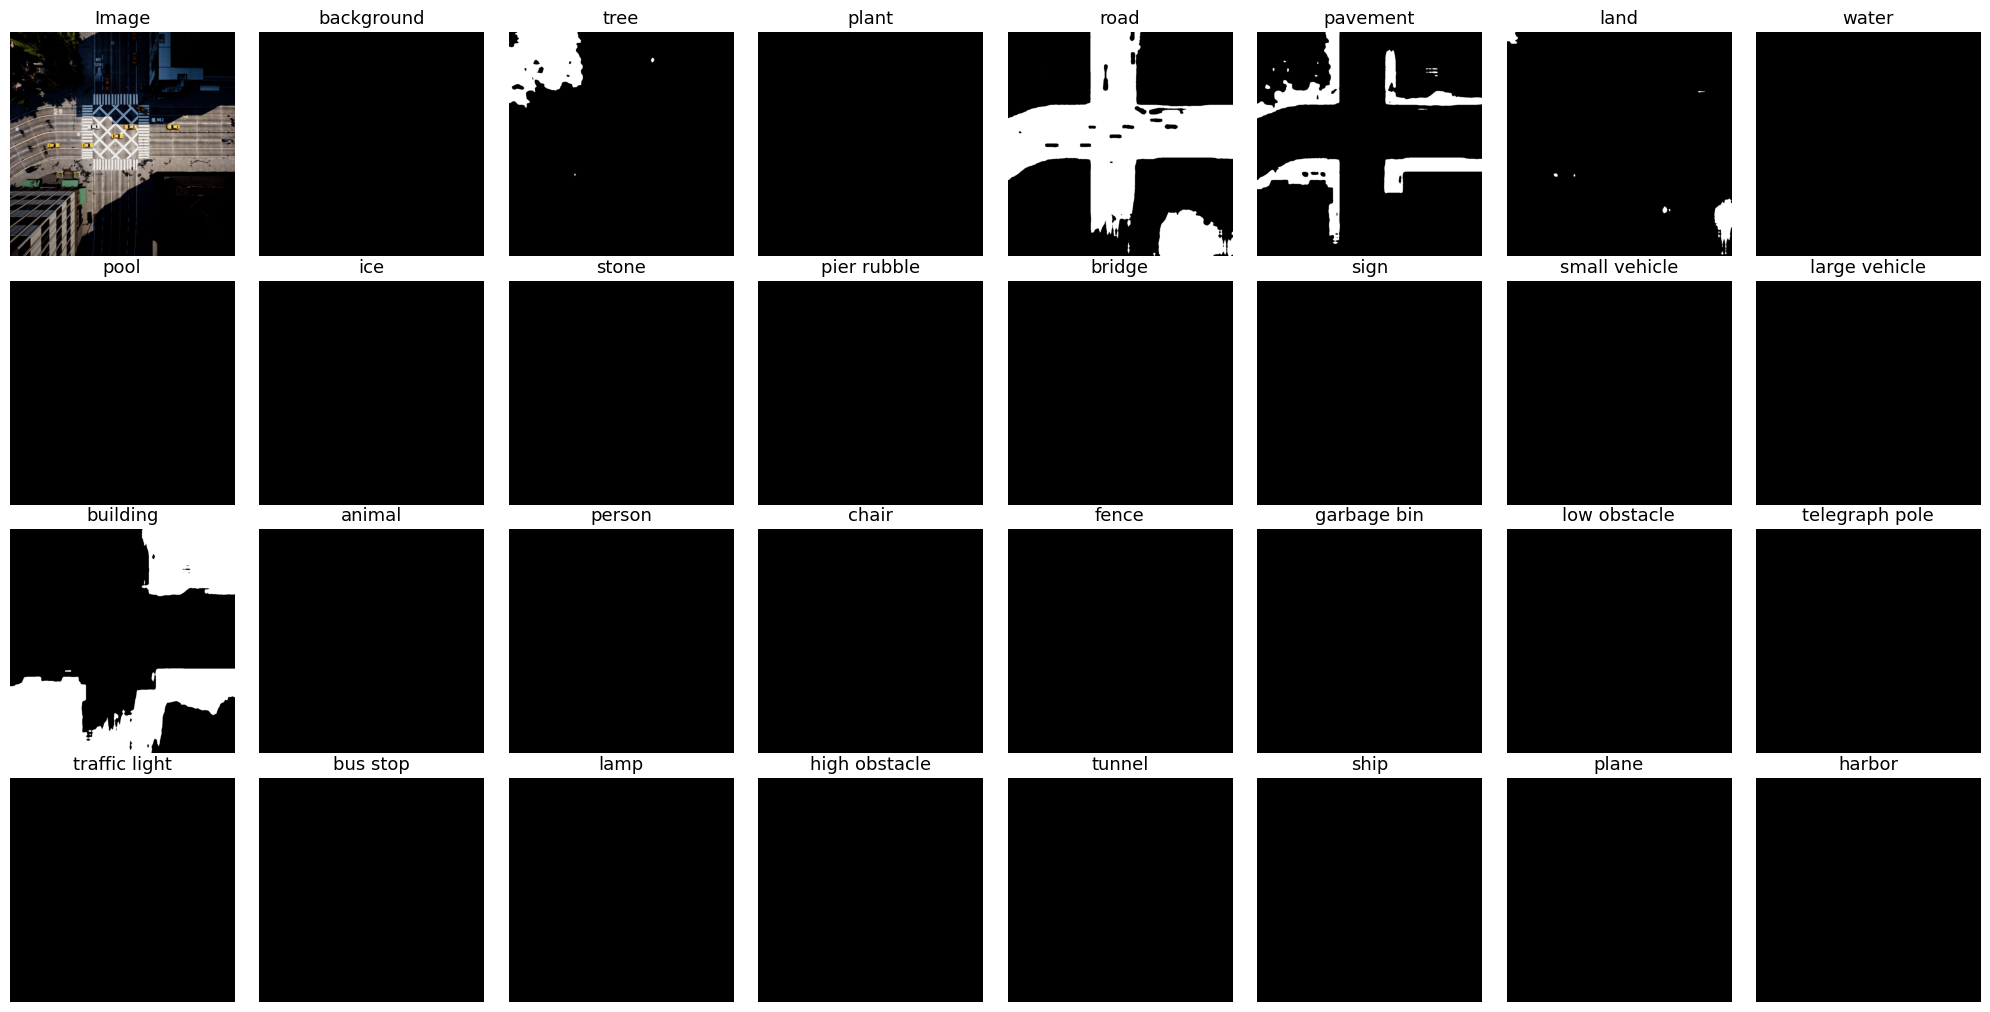

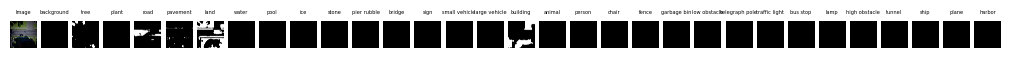

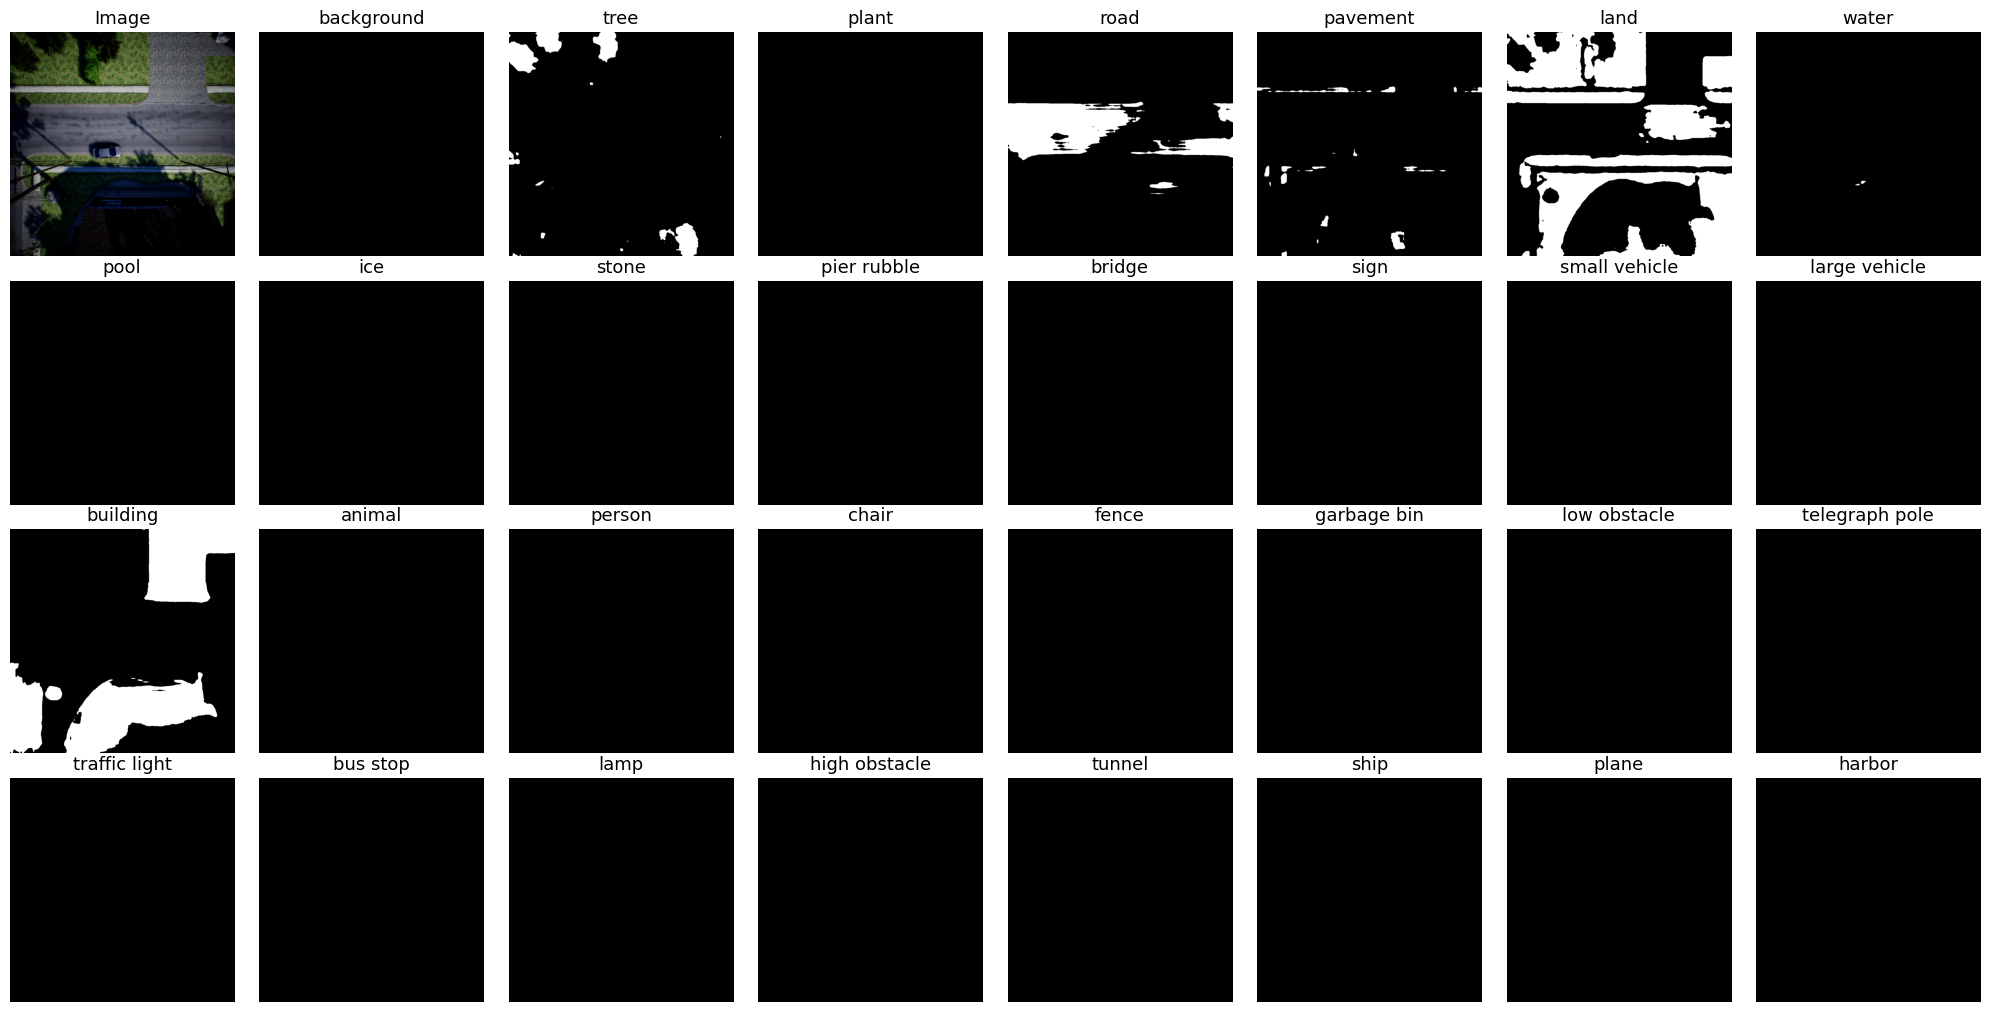

In [ ]:
model_path = "./data/experiments/valid_semantic_segmentation/checkpoint.pth.tar"
labels = ["background","tree","plant","road","pavement","land","water","pool","ice","stone","pier rubble","bridge","sign",
        "small vehicle","large vehicle","building","animal","person","chair","fence","garbage bin","low obstacle",
        "telegraph pole","traffic light","bus stop","lamp","high obstacle","tunnel","ship","plane","harbor"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
plt.rcParams.update({'font.size': 3})
csv_file = "./data/valid_semantic_segmentation/valid_test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[1]+'/'+lines[0])

image = image_loader('./data/valid_semantic_segmentation/images/' + test_list[0])[:,:,:3]
fig = model.predict_masks(image, labels, transform)
new_fig = rearrange_figure_to_grid(fig, cols=8)
new_fig.show()

image = image_loader('./data/valid_semantic_segmentation/images/' + test_list[1])[:,:,:3]
fig = model.predict_masks(image, labels, transform)
new_fig = rearrange_figure_to_grid(fig, cols=8)
new_fig.show()